# k-Nearest Neighbours and Model Evaluation

The theory is in [README.md](./README.md) — the algorithm, distance metrics, the curse of
dimensionality, cross-validation and the metrics. This notebook is one worked example.

The dataset is **wine**: 178 bottles, thirteen chemical measurements each, three cultivars. One
question runs through the whole notebook — *how good is this classifier?* — and most of the work
goes into showing how many ways there are to answer it wrongly.

Everything is written in plain Python, as in week 6: lists, loops and `math`, with no NumPy and no
scikit-learn. The classifier, the stratified split, the cross-validation, the confusion matrix and
the kd-tree are all here in full. That is deliberate — this week the thing being taught *is* the
measurement machinery, and a library call like `cross_val_score(pipe, X, y, cv=folds)` is exactly
the place where the interesting decisions go invisible. Matplotlib is used for pictures only.

Your homework is to rebuild kNN, the normalisation, the stratified split and the 10-fold
cross-validation in C++, on a different dataset. Read this for the reasoning rather than for lines
to copy.

## Setup

In [1]:
from __future__ import annotations

import csv
import heapq
import math
import random
import sys
from collections import Counter
from dataclasses import dataclass, field
from typing import Sequence

import matplotlib.pyplot as plt

sys.setrecursionlimit(100_000)

Vector = list[float]
Matrix = list[Vector]
Labels = list[int]

SEED = 1
K_VALUES = [1, 3, 5, 9, 15, 25, 35, 51]


def mean(values: Sequence[float]) -> float:
    return sum(values) / len(values)


def std(values: Sequence[float]) -> float:
    mu = mean(values)
    return math.sqrt(sum((value - mu) ** 2 for value in values) / len(values))


def transpose(X: Matrix) -> Matrix:
    return [list(column) for column in zip(*X)]


def take(rows: list, indices: list[int]) -> list:
    return [rows[i] for i in indices]


def linspace(start: float, stop: float, count: int) -> Vector:
    step = (stop - start) / (count - 1)
    return [start + step * i for i in range(count)]

## The data

Thirteen measurements taken from a chemical analysis of wines grown in the same region of Italy by
three different cultivators. The task is to recover the cultivar from the chemistry.

The column to watch is the last one.

In [2]:
def load_csv(path: str, target: str) -> tuple[Matrix, Labels, list[str]]:
    with open(path, newline="") as handle:
        rows = list(csv.DictReader(handle))
    names = [name for name in rows[0] if name != target]
    X = [[float(row[name]) for name in names] for row in rows]
    y = [int(float(row[target])) for row in rows]
    return X, y, names


X, y, feature_names = load_csv("wine.csv", "target")
class_names = ["class_0", "class_1", "class_2"]
sizes = Counter(y)

print(f"{len(X)} bottles, {len(feature_names)} measurements, {len(class_names)} cultivars")
print(f"class sizes: {[sizes[c] for c in sorted(sizes)]}\n")

print(f"{'measurement':<32}{'min':>9}{'max':>9}{'std':>9}")
columns = transpose(X)
for name, column in zip(feature_names, columns):
    print(f"{name:<32}{min(column):>9.2f}{max(column):>9.2f}{std(column):>9.2f}")

spread = [std(column) for column in columns]
widest = max(range(len(spread)), key=lambda i: spread[i])
narrowest = min(range(len(spread)), key=lambda i: spread[i])
print(f"\n{feature_names[widest]} varies {spread[widest] / spread[narrowest]:.0f}x more "
      f"than {feature_names[narrowest]}")

178 bottles, 13 measurements, 3 cultivars
class sizes: [59, 71, 48]

measurement                           min      max      std
alcohol                             11.03    14.83     0.81
malic_acid                           0.74     5.80     1.11
ash                                  1.36     3.23     0.27
alcalinity_of_ash                   10.60    30.00     3.33
magnesium                           70.00   162.00    14.24
total_phenols                        0.98     3.88     0.62
flavanoids                           0.34     5.08     1.00
nonflavanoid_phenols                 0.13     0.66     0.12
proanthocyanins                      0.41     3.58     0.57
color_intensity                      1.28    13.00     2.31
hue                                  0.48     1.71     0.23
od280_od315_of_diluted_wines         1.27     4.00     0.71
proline                            278.00  1680.00   314.02

proline varies 2530x more than nonflavanoid_phenols


## What "nearest" means

kNN needs a notion of distance, and the usual family is the Minkowski distance:

    D(x, y) = (Σᵢ |xᵢ - yᵢ|^p)^(1/p)

Drawing the set of points at distance 1 from the origin shows what each `p` considers equally far
away. The shape changes, and with it which neighbours win.

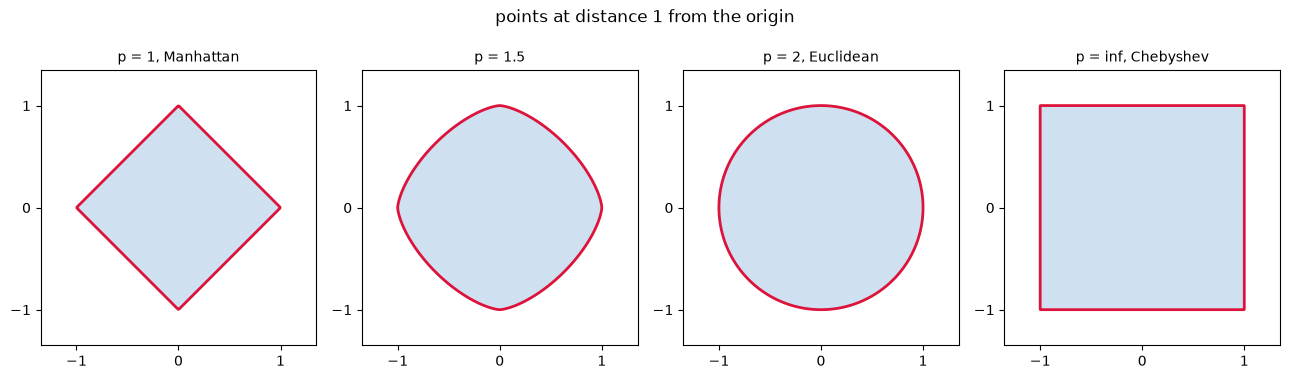

In [3]:
def minkowski(a: Vector, b: Vector, p: float = 2.0) -> float:
    if math.isinf(p):
        return max(abs(ai - bi) for ai, bi in zip(a, b))
    if p == 2.0:
        return math.sqrt(sum((ai - bi) ** 2 for ai, bi in zip(a, b)))
    if p == 1.0:
        return sum(abs(ai - bi) for ai, bi in zip(a, b))
    return sum(abs(ai - bi) ** p for ai, bi in zip(a, b)) ** (1.0 / p)


axis_points = linspace(-1.35, 1.35, 300)
origin = [0.0, 0.0]

fig, axes = plt.subplots(1, 4, figsize=(13, 3.4))
for ax, (p, label) in zip(axes, [(1.0, "p = 1, Manhattan"), (1.5, "p = 1.5"),
                                 (2.0, "p = 2, Euclidean"), (math.inf, "p = inf, Chebyshev")]):
    gx = [[x for x in axis_points] for _ in axis_points]
    gy = [[v for _ in axis_points] for v in axis_points]
    distance = [[minkowski([x, v], origin, p) for x in axis_points] for v in axis_points]
    ax.contourf(gx, gy, distance, levels=[0, 1], colors=["#cfe0f0"])
    ax.contour(gx, gy, distance, levels=[1], colors=["crimson"], linewidths=2)
    ax.set_title(label, fontsize=10)
    ax.set_aspect("equal"), ax.set_xticks([-1, 0, 1]), ax.set_yticks([-1, 0, 1])
fig.suptitle("points at distance 1 from the origin", y=1.04)
fig.tight_layout()
plt.show()

## Scaling decides everything

Distance adds up contributions from every feature, so a feature measured in bigger units counts for
more — purely because of its units, not because it matters more.

`proline` runs to 1680 and `nonflavanoid_phenols` to 0.66. Euclidean distance on the raw numbers is
very nearly the distance in `proline` alone.

Everything below uses the same split: 80/20, stratified so the three cultivars keep their
proportions in both halves.

In [4]:
@dataclass
class Standardiser:
    means: Vector
    stds: Vector

    @classmethod
    def fit(cls, X: Matrix) -> "Standardiser":
        columns = transpose(X)
        return cls(means=[mean(c) for c in columns], stds=[std(c) or 1.0 for c in columns])

    def transform(self, X: Matrix) -> Matrix:
        return [
            [(value - mu) / sigma for value, mu, sigma in zip(row, self.means, self.stds)]
            for row in X
        ]


@dataclass
class KNearestNeighbours:
    k: int = 5
    p: float = 2.0
    X: Matrix = field(default_factory=list)
    y: Labels = field(default_factory=list)

    def fit(self, X: Matrix, y: Labels) -> "KNearestNeighbours":
        self.X, self.y = X, y
        return self

    def neighbours(self, q: Vector) -> list[tuple[float, int]]:
        return sorted((minkowski(row, q, self.p), i) for i, row in enumerate(self.X))[: self.k]

    def predict_one(self, q: Vector) -> int:
        votes = Counter(self.y[i] for _, i in self.neighbours(q))
        most = max(votes.values())
        return min(label for label, count in votes.items() if count == most)

    def predict(self, X: Matrix) -> Labels:
        return [self.predict_one(row) for row in X]


def accuracy(y: Labels, predicted: Labels) -> float:
    return sum(1 for actual, guess in zip(y, predicted) if actual == guess) / len(y)


def stratified_split(y: Labels, test_fraction: float, seed: int) -> tuple[list[int], list[int]]:
    rng = random.Random(seed)
    train: list[int] = []
    test: list[int] = []
    for label in sorted(set(y)):
        members = [i for i, value in enumerate(y) if value == label]
        rng.shuffle(members)
        cut = round(test_fraction * len(members))
        test.extend(members[:cut])
        train.extend(members[cut:])
    rng.shuffle(train), rng.shuffle(test)
    return train, test


train, test = stratified_split(y, 0.2, seed=SEED)
X_train, X_test = take(X, train), take(X, test)
y_train, y_test = take(y, train), take(y, test)

train_sizes, test_sizes = Counter(y_train), Counter(y_test)
print(f"train {len(y_train)} bottles {[train_sizes[c] for c in sorted(train_sizes)]}, "
      f"test {len(y_test)} bottles {[test_sizes[c] for c in sorted(test_sizes)]}\n")

scaler = Standardiser.fit(X_train)
Z_train, Z_test = scaler.transform(X_train), scaler.transform(X_test)

print(f"{'features':<18}{'train':>9}{'test':>9}")
for label, (fit_X, score_X) in (("raw", (X_train, X_test)), ("standardised", (Z_train, Z_test))):
    model = KNearestNeighbours(5).fit(fit_X, y_train)
    print(f"{label:<18}{accuracy(y_train, model.predict(fit_X)):>9.3f}"
          f"{accuracy(y_test, model.predict(score_X)):>9.3f}")

train 142 bottles [47, 57, 38], test 36 bottles [12, 14, 10]

features              train     test
raw                   0.789    0.722
standardised          0.965    1.000


From 0.722 to 1.000 for three lines of arithmetic that change nothing about the algorithm. No
choice of `k` below will come close to mattering this much.

Note also how the scaler is applied. `Standardiser.fit` sees the **training** rows only, and the
same fitted object then transforms the test rows. Fitting the scaler on all the data before
splitting leaks information from the test set into training — a quiet, common, and completely
invisible mistake, and the reason the means and standard deviations live in an object rather than
in two loose variables.

Inside cross-validation below the same rule applies per fold, which is why `cross_val_scores`
re-fits the scaler on every one.

## Choosing k

`k = 1` classifies by the single closest bottle; large `k` averages over a wide neighbourhood.
Small `k` means high variance, large `k` means high bias, and the honest way to choose is
cross-validation **on the training set**.

In [5]:
def stratified_folds(y: Labels, n_folds: int, seed: int) -> list[list[int]]:
    rng = random.Random(seed)
    folds: list[list[int]] = [[] for _ in range(n_folds)]
    for label in sorted(set(y)):
        members = [i for i, value in enumerate(y) if value == label]
        rng.shuffle(members)
        for position, index in enumerate(members):
            folds[position % n_folds].append(index)
    return folds


def cross_val_scores(X: Matrix, y: Labels, k: int, n_folds: int = 10, seed: int = 0) -> list[float]:
    folds = stratified_folds(y, n_folds, seed)
    scores: list[float] = []
    for held_out in range(n_folds):
        validation = folds[held_out]
        training = [i for f in range(n_folds) if f != held_out for i in folds[f]]
        fold_scaler = Standardiser.fit(take(X, training))
        model = KNearestNeighbours(k).fit(fold_scaler.transform(take(X, training)), take(y, training))
        predicted = model.predict(fold_scaler.transform(take(X, validation)))
        scores.append(accuracy(take(y, validation), predicted))
    return scores


print(f"{'k':>4}{'train':>9}{'CV mean':>10}{'CV std':>9}{'test':>9}")
for k in K_VALUES:
    scores = cross_val_scores(X_train, y_train, k, seed=0)
    model = KNearestNeighbours(k).fit(Z_train, y_train)
    print(f"{k:>4}{accuracy(y_train, model.predict(Z_train)):>9.3f}{mean(scores):>10.3f}"
          f"{std(scores):>9.3f}{accuracy(y_test, model.predict(Z_test)):>9.3f}")

   k    train   CV mean   CV std     test
   1    1.000     0.943    0.045    0.944
   3    0.958     0.930    0.046    1.000


   5    0.965     0.944    0.029    1.000
   9    0.972     0.944    0.041    0.972


  15    0.972     0.951    0.044    0.972


  25    0.979     0.972    0.035    1.000
  35    0.972     0.972    0.035    0.972


  51    0.965     0.951    0.053    0.944


Read the first row before anything else. **`k = 1` scores exactly 1.000 on the training set**, and
it always will — the nearest neighbour of a training point is itself. That perfect score measures
nothing at all, and it is the cleanest example of overfitting in the course.

Now read the rest, and notice that it is mostly noise. The CV standard deviations are 3 to 5
percentage points, which is larger than the gaps between the values of `k`. The test column bounces
between 0.944 and 1.000 without a pattern — unsurprising, since it has 36 entries, so a single
bottle is worth 2.8%.

On this evidence you cannot rank `k` at all. The fix is not a bigger model but more measurements.

In [6]:
REPEATS = 20

averaged: dict[int, float] = {}
spread: dict[int, float] = {}
for k in K_VALUES:
    repeated = [mean(cross_val_scores(X_train, y_train, k, seed=s)) for s in range(REPEATS)]
    averaged[k], spread[k] = mean(repeated), std(repeated)

print(f"10-fold CV repeated over {REPEATS} shuffles\n")
print(f"{'k':>4}{'mean':>9}{'std of the mean':>18}")
for k in K_VALUES:
    print(f"{k:>4}{averaged[k]:>9.4f}{spread[k]:>18.4f}")
print(f"\nbest k: {max(K_VALUES, key=lambda key: averaged[key])}")

10-fold CV repeated over 20 shuffles

   k     mean   std of the mean
   1   0.9494            0.0039
   3   0.9339            0.0117
   5   0.9386            0.0062
   9   0.9582            0.0087
  15   0.9616            0.0074
  25   0.9712            0.0049
  35   0.9670            0.0052
  51   0.9553            0.0055

best k: 25


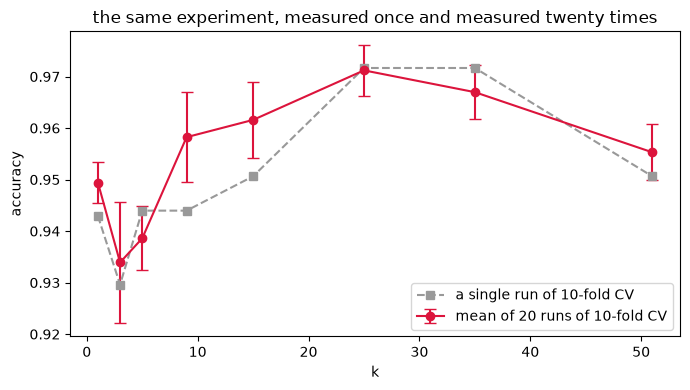

In [7]:
single = [mean(cross_val_scores(X_train, y_train, k, seed=0)) for k in K_VALUES]

fig, ax = plt.subplots(figsize=(7, 4))
ax.errorbar(K_VALUES, [averaged[k] for k in K_VALUES], yerr=[spread[k] for k in K_VALUES],
            marker="o", color="crimson", capsize=4,
            label=f"mean of {REPEATS} runs of 10-fold CV")
ax.plot(K_VALUES, single, marker="s", color="0.6", ls="--", label="a single run of 10-fold CV")
ax.set_xlabel("k"), ax.set_ylabel("accuracy"), ax.legend()
ax.set_title("the same experiment, measured once and measured twenty times")
fig.tight_layout()
plt.show()

The grey line is what one cross-validation run told us: a jagged mess with no clear message. The red
line is the same quantity measured twenty times, and now the shape is obvious — a dip at `k = 3`,
a climb to a peak in the twenties, and a fall away by `k = 51`. Error bars around half a percentage
point, and under half for most of the curve.

Nothing about the model changed. Only how many times it was measured.

**The rule this section exists to teach:** choose `k` from the red line, then touch the test set
once. Choosing `k` by test accuracy and then reporting that accuracy is reporting the best of eight
tries on 36 examples, which is a different and much smaller claim than it appears to be.

### When k earns its keep

On clean wine data the choice of `k` barely matters. Add thirty columns of pure noise and it
matters a great deal, because averaging over more neighbours is what cancels noise out.

In [8]:
noise_rng = random.Random(0)
X_noisy = [row + [noise_rng.gauss(0.0, 1.0) for _ in range(30)] for row in X]
Xn_train, Xn_test = take(X_noisy, train), take(X_noisy, test)

noisy_scaler = Standardiser.fit(Xn_train)
Zn_train, Zn_test = noisy_scaler.transform(Xn_train), noisy_scaler.transform(Xn_test)

print("13 real features + 30 of pure noise\n")
print(f"{'k':>4}{'train':>9}{'CV mean':>10}{'CV std':>9}{'test':>9}")
for k in K_VALUES:
    scores = cross_val_scores(Xn_train, y_train, k, seed=0)
    model = KNearestNeighbours(k).fit(Zn_train, y_train)
    print(f"{k:>4}{accuracy(y_train, model.predict(Zn_train)):>9.3f}{mean(scores):>10.3f}"
          f"{std(scores):>9.3f}{accuracy(y_test, model.predict(Zn_test)):>9.3f}")

13 real features + 30 of pure noise

   k    train   CV mean   CV std     test
   1    1.000     0.838    0.094    0.861


   3    0.965     0.888    0.085    0.944
   5    0.951     0.902    0.079    0.944


   9    0.944     0.895    0.089    0.972
  15    0.930     0.924    0.055    0.972


  25    0.944     0.936    0.051    0.917
  35    0.958     0.951    0.044    1.000


  51    0.965     0.957    0.047    0.972


`k = 1` falls to 0.838 while `k = 51` holds 0.957. The noise is what `k` is defending against, and
with none of it around there was nothing to defend.

## Reading the mistakes

Accuracy is one number covering every class. The **confusion matrix** is the same information
before it was flattened: rows are the true cultivar, columns the predicted one, so the diagonal is
what went right and every other cell names a specific mistake.

The scaled model makes no mistakes, so the unscaled one is the instructive half.

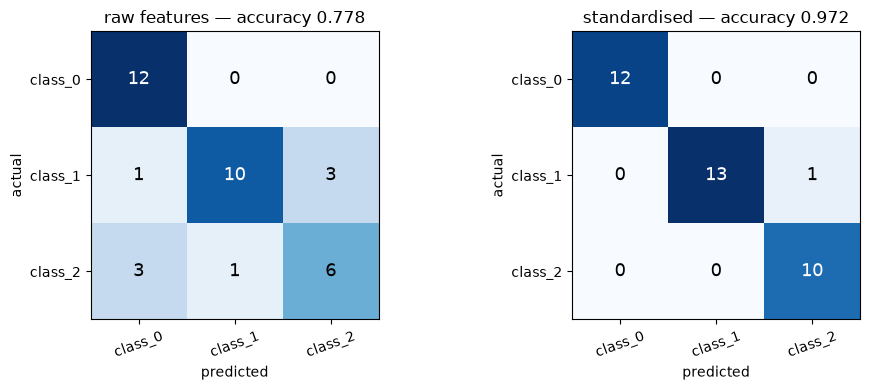

              precision   recall      f1  support
class_0           0.750    1.000   0.857       12
class_1           0.909    0.714   0.800       14
class_2           0.667    0.600   0.632       10
accuracy                           0.778       36


In [9]:
def confusion_matrix(y: Labels, predicted: Labels, n_classes: int) -> list[list[int]]:
    matrix = [[0] * n_classes for _ in range(n_classes)]
    for actual, guess in zip(y, predicted):
        matrix[actual][guess] += 1
    return matrix


def precision_recall_f1(y: Labels, predicted: Labels, positive: int) -> tuple[float, float, float]:
    true_positive = sum(1 for a, b in zip(y, predicted) if a == positive and b == positive)
    false_positive = sum(1 for a, b in zip(y, predicted) if a != positive and b == positive)
    false_negative = sum(1 for a, b in zip(y, predicted) if a == positive and b != positive)
    precision = true_positive / (true_positive + false_positive) if true_positive + false_positive else 0.0
    recall = true_positive / (true_positive + false_negative) if true_positive + false_negative else 0.0
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
    return precision, recall, f1


def classification_report(y: Labels, predicted: Labels, names: list[str]) -> None:
    print(f"{'':<12}{'precision':>11}{'recall':>9}{'f1':>8}{'support':>9}")
    for index, name in enumerate(names):
        precision, recall, f1 = precision_recall_f1(y, predicted, index)
        print(f"{name:<12}{precision:>11.3f}{recall:>9.3f}{f1:>8.3f}{y.count(index):>9}")
    print(f"{'accuracy':<12}{'':<11}{'':<9}{accuracy(y, predicted):>8.3f}{len(y):>9}")


fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (label, fit_X, score_X) in zip(axes, (("raw features", X_train, X_test),
                                              ("standardised", Z_train, Z_test))):
    predicted = KNearestNeighbours(9).fit(fit_X, y_train).predict(score_X)
    matrix = confusion_matrix(y_test, predicted, 3)
    largest = max(max(row) for row in matrix)
    ax.imshow(matrix, cmap="Blues", vmin=0, vmax=largest)
    for i, row in enumerate(matrix):
        for j, value in enumerate(row):
            ax.text(j, i, value, ha="center", va="center",
                    color="white" if value > largest / 2 else "black", fontsize=13)
    ax.set_xticks(range(3), class_names, rotation=20)
    ax.set_yticks(range(3), class_names)
    ax.set_xlabel("predicted"), ax.set_ylabel("actual")
    ax.set_title(f"{label} — accuracy {accuracy(y_test, predicted):.3f}")
fig.tight_layout()
plt.show()

classification_report(y_test, KNearestNeighbours(9).fit(X_train, y_train).predict(X_test), class_names)

The raw model's failure has a shape. Every real `class_0` bottle is found — recall 1.000 — but a
quarter of the bottles it *calls* `class_0` are something else, so precision is only 0.750.
`class_2` fails the other way round: it finds 0.600 of the real ones, and a third of its `class_2`
calls are wrong. `class_1` leaks in both directions at once. One accuracy figure of 0.778 says none
of that, and the three classes are not failing for the same reason.

    Precision = TP / (TP + FP)      of the ones flagged, how many were right
    Recall    = TP / (TP + FN)      of the ones there were, how many were found
    F1        = 2PR / (P + R)

## When accuracy lies outright

The worst case for accuracy is a rare class. Here is the same data reshaped into "is this bottle
`class_2`?", with `class_2` down-sampled so it is about 9% of the data — the shape of a fraud
detector, a disease screen, or a defect test.

In [10]:
rare_rng = random.Random(3)
positive = [i for i, value in enumerate(y) if value == 2]
negative = [i for i, value in enumerate(y) if value != 2]
subset = negative + rare_rng.sample(positive, 12)

X_rare = take(X, subset)
y_rare = [1 if y[i] == 2 else 0 for i in subset]

rare_train, rare_test = stratified_split(y_rare, 0.4, seed=2)
Xr_train, Xr_test = take(X_rare, rare_train), take(X_rare, rare_test)
yr_train, yr_test = take(y_rare, rare_train), take(y_rare, rare_test)

print(f"{len(y_rare)} bottles, {sum(y_rare)} positive ({sum(y_rare) / len(y_rare):.1%})")
print(f"test set: {len(yr_test)} bottles, {sum(yr_test)} positive\n")

rare_scaler = Standardiser.fit(Xr_train)
majority = max(set(yr_train), key=yr_train.count)

predictions = {
    'always predict "no"': [majority] * len(yr_test),
    "kNN, raw features": KNearestNeighbours(5).fit(Xr_train, yr_train).predict(Xr_test),
    "kNN, standardised": KNearestNeighbours(5)
                         .fit(rare_scaler.transform(Xr_train), yr_train)
                         .predict(rare_scaler.transform(Xr_test)),
}

print(f"{'model':<22}{'accuracy':>10}{'precision':>11}{'recall':>9}{'F1':>7}   confusion")
for label, predicted in predictions.items():
    precision, recall, f1 = precision_recall_f1(yr_test, predicted, positive=1)
    print(f"{label:<22}{accuracy(yr_test, predicted):>10.3f}{precision:>11.3f}{recall:>9.3f}"
          f"{f1:>7.3f}   {confusion_matrix(yr_test, predicted, 2)}")

142 bottles, 12 positive (8.5%)
test set: 57 bottles, 5 positive

model                   accuracy  precision   recall     F1   confusion
always predict "no"        0.912      0.000    0.000  0.000   [[52, 0], [5, 0]]
kNN, raw features          0.912      0.000    0.000  0.000   [[52, 0], [5, 0]]
kNN, standardised          0.982      1.000    0.800  0.889   [[52, 0], [1, 4]]


The first two rows have **identical accuracy**, and both are worthless: neither finds a single
positive case. A model that has learned nothing at all and a model that has learned nothing useful
are indistinguishable by accuracy, and separated instantly by recall.

Whenever one class is rare, quote precision and recall, or quote the confusion matrix and let the
reader work it out. Accuracy on imbalanced data is not a weak measurement — it is a misleading one.

## kd-trees: neighbours without measuring everything

Every prediction so far measured the distance to all 142 training bottles — that is what
`KNearestNeighbours.neighbours` does, and it is the only thing about kNN that is slow. Fine here,
hopeless for millions of points, so this section builds the standard fix: a **kd-tree**.

The cost to watch is the number of **distances measured**, not seconds. Both the tree and brute
force are plain Python here and share the same `minkowski`, so counting measurements compares two
algorithms rather than two implementations — `KDTree.measured` is reset by every query and counts
exactly the distances that were computed.

Three pieces:

- **Build.** Take the feature with the widest spread, put the median point along it in the node,
  everything below it in the left subtree and everything above it in the right, and recurse. The
  median keeps the tree balanced, about `log₂ N` levels deep.
- **Search.** Keep the best `k` found so far in a max-heap, so the worst of them is on top. Walk
  into the query's own side of each split first.
- **Prune.** Every point on the far side of a split differs from the query by at least the
  distance to the splitting plane in that one feature, and a Minkowski distance is never smaller
  than one feature's difference. So when the plane is farther away than the current `k`-th best,
  the whole far subtree is skipped, unmeasured.

In [11]:
@dataclass
class Node:
    point: int
    axis: int
    left: "Node | None" = None
    right: "Node | None" = None


class KDTree:
    def __init__(self, X: Matrix, p: float = 2.0) -> None:
        self.X, self.p = X, p
        self.measured = 0
        self.root = self._build(list(range(len(X))))

    def _build(self, indices: list[int]) -> "Node | None":
        if not indices:
            return None
        axes = range(len(self.X[0]))
        spreads = [max(self.X[i][a] for i in indices) - min(self.X[i][a] for i in indices)
                   for a in axes]
        axis = max(axes, key=lambda a: spreads[a])
        indices.sort(key=lambda i: self.X[i][axis])
        middle = len(indices) // 2
        return Node(
            point=indices[middle],
            axis=axis,
            left=self._build(indices[:middle]),
            right=self._build(indices[middle + 1:]),
        )

    def query(self, q: Vector, k: int, trace: list | None = None) -> list[tuple[float, int]]:
        self.measured = 0
        best: list[tuple[float, int]] = []
        self._search(self.root, q, k, best, trace)
        return sorted((-d, -i) for d, i in best)

    def _search(self, node: "Node | None", q: Vector, k: int,
                best: list[tuple[float, int]], trace: list | None) -> None:
        if node is None:
            return
        distance = minkowski(self.X[node.point], q, self.p)
        self.measured += 1
        heapq.heappush(best, (-distance, -node.point))
        if len(best) > k:
            heapq.heappop(best)
        if trace is not None:
            trace.append(("visit", node.point, distance, -best[0][0]))

        offset = q[node.axis] - self.X[node.point][node.axis]
        near, far = (node.left, node.right) if offset <= 0 else (node.right, node.left)
        self._search(near, q, k, best, trace)
        if len(best) < k or abs(offset) <= -best[0][0]:
            self._search(far, q, k, best, trace)
        elif trace is not None:
            trace.append(("prune", node.point, abs(offset), -best[0][0]))


def brute_force(X: Matrix, q: Vector, k: int, p: float = 2.0) -> list[tuple[float, int]]:
    return sorted((minkowski(row, q, p), i) for i, row in enumerate(X))[:k]

### Six points by hand

The same example as the README, small enough to follow every step. The tree is printed with each
node's split; then a query traces which nodes it visits and which subtree it never enters.

In [12]:
corners: Matrix = [[2.0, 3.0], [5.0, 4.0], [9.0, 6.0], [4.0, 7.0], [8.0, 1.0], [7.0, 2.0]]
names = "ABCDEF"
small = KDTree(corners)


def show(node: "Node | None", depth: int = 0, side: str = "root") -> None:
    if node is None:
        return
    leaf = node.left is None and node.right is None
    split = "a leaf" if leaf else f"splits on {'xy'[node.axis]} = {corners[node.point][node.axis]:g}"
    point = corners[node.point]
    print(f"{'    ' * depth}{side:>5}: {names[node.point]}({point[0]:g}, {point[1]:g})  {split}")
    show(node.left, depth + 1, "left")
    show(node.right, depth + 1, "right")


show(small.root)

trace: list = []
nearest = small.query([3.0, 4.0], k=1, trace=trace)
print("\nquery (3, 4), k = 1:")
for kind, i, value, worst in trace:
    if kind == "visit":
        print(f"  visit {names[i]}: distance {value:.2f}   (best so far {worst:.2f})")
    else:
        print(f"  skip everything on the far side of {names[i]}: the split is {value:.2f} away, "
              f"more than {worst:.2f}")
print(f"nearest: {names[nearest[0][1]]}, after {small.measured} of {len(corners)} distances")

 root: F(7, 2)  splits on x = 7
     left: B(5, 4)  splits on y = 4
         left: A(2, 3)  a leaf
        right: D(4, 7)  a leaf
    right: C(9, 6)  splits on y = 6
         left: E(8, 1)  a leaf

query (3, 4), k = 1:
  visit F: distance 4.47   (best so far 4.47)
  visit B: distance 2.00   (best so far 2.00)
  visit A: distance 1.41   (best so far 1.41)
  visit D: distance 3.16   (best so far 1.41)
  skip everything on the far side of F: the split is 4.00 away, more than 1.41
nearest: A, after 4 of 6 distances


### First it has to be right

A fast search that returns different neighbours is a bug, so before counting anything, compare it
with brute force: the same `(distance, index)` lists, for every test bottle and every `k` from 1 to
20, on the standardised data.

In [13]:
tree = KDTree(Z_train)

mismatches = 0
measured: list[int] = []
for k in range(1, 21):
    for q in Z_test:
        if tree.query(q, k) != brute_force(Z_train, q, k):
            mismatches += 1
        measured.append(tree.measured)

print(f"{len(measured)} queries: {mismatches} differ from brute force")
print(f"distances measured per query: {mean(measured):.0f} of {len(Z_train)} on average "
      f"({mean(measured) / len(Z_train):.0%})")

720 queries: 0 differ from brute force
distances measured per query: 139 of 142 on average (98%)


### What it skips

The pruning is easiest to see in two dimensions. Three hundred random points, the splits drawn as
the tree made them, and one query asking for its five nearest neighbours.

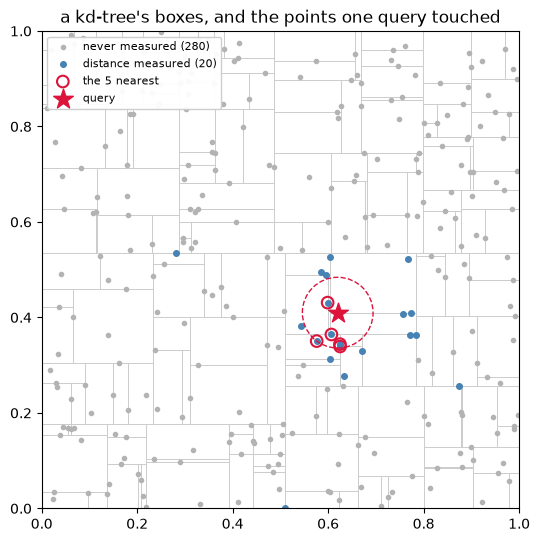

In [14]:
plane_rng = random.Random(4)
points: Matrix = [[plane_rng.random(), plane_rng.random()] for _ in range(300)]
plane = KDTree(points)
query, k_near = [0.62, 0.41], 5

plane_trace: list = []
found = plane.query(query, k_near, trace=plane_trace)
visited = sorted({i for kind, i, *_ in plane_trace if kind == "visit"})
never = [i for i in range(len(points)) if i not in set(visited)]

fig, ax = plt.subplots(figsize=(6.2, 6.2))


def draw(node: "Node | None", x0: float, x1: float, y0: float, y1: float) -> None:
    if node is None or (node.left is None and node.right is None):
        return
    value = points[node.point][node.axis]
    if node.axis == 0:
        ax.plot([value, value], [y0, y1], color="0.8", lw=0.7, zorder=0)
        draw(node.left, x0, value, y0, y1), draw(node.right, value, x1, y0, y1)
    else:
        ax.plot([x0, x1], [value, value], color="0.8", lw=0.7, zorder=0)
        draw(node.left, x0, x1, y0, value), draw(node.right, x0, x1, value, y1)


draw(plane.root, 0.0, 1.0, 0.0, 1.0)
ax.scatter([points[i][0] for i in never], [points[i][1] for i in never],
           s=9, color="0.7", label=f"never measured ({len(never)})")
ax.scatter([points[i][0] for i in visited], [points[i][1] for i in visited],
           s=16, color="steelblue", label=f"distance measured ({len(visited)})")
ax.scatter([points[i][0] for _, i in found], [points[i][1] for _, i in found],
           s=70, facecolor="none", edgecolor="crimson", lw=1.5, label=f"the {k_near} nearest")
ax.scatter(*query, marker="*", s=220, color="crimson", zorder=3, label="query")
ax.add_patch(plt.Circle(query, found[-1][0], fill=False, ls="--", color="crimson"))
ax.set_xlim(0, 1), ax.set_ylim(0, 1), ax.set_aspect("equal")
ax.set_title("a kd-tree's boxes, and the points one query touched")
ax.legend(loc="upper left", fontsize=8, framealpha=0.95)
plt.show()

The dashed circle is the distance to the fifth nearest point. Any box that does not reach into it
was skipped whole. Now the two questions that decide whether a kd-tree is worth having: how does
the cost grow with the number of points, and with the number of features?

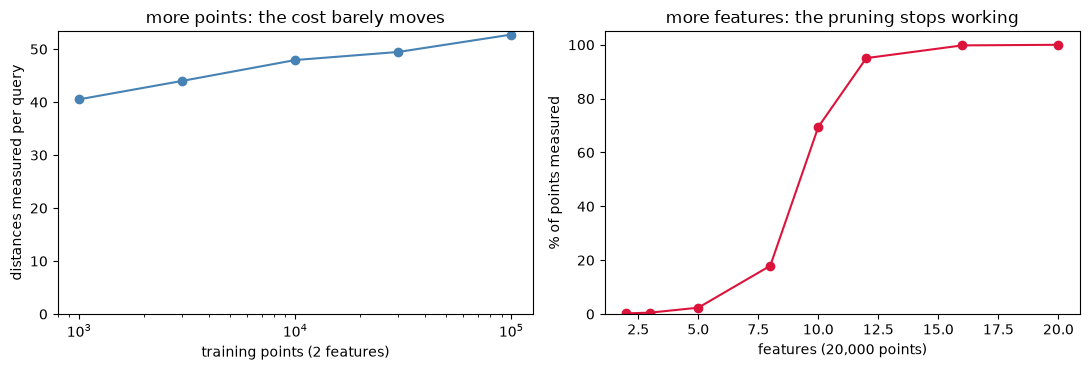

    points   measured per query
     1,000                 40.5
     3,000                 44.0
    10,000                 47.9
    30,000                 49.5
   100,000                 52.8

  features   share measured
         2             0.2%
         3             0.5%
         5             2.4%
         8            17.9%
        10            69.5%
        12            95.1%
        16            99.8%
        20           100.0%


In [15]:
def average_measured(cloud: KDTree, probes: Matrix, k: int = 10) -> float:
    costs = []
    for q in probes:
        cloud.query(q, k)
        costs.append(cloud.measured)
    return mean(costs)


sizes = [1_000, 3_000, 10_000, 30_000, 100_000]
cost = []
for n in sizes:
    build_rng = random.Random(0)
    cloud = KDTree([[build_rng.random(), build_rng.random()] for _ in range(n)])
    probe_rng = random.Random(1)
    cost.append(average_measured(cloud, [[probe_rng.random(), probe_rng.random()]
                                         for _ in range(200)]))

dims = [2, 3, 5, 8, 10, 12, 16, 20]
share = []
for d in dims:
    build_rng = random.Random(0)
    cloud = KDTree([[build_rng.random() for _ in range(d)] for _ in range(20_000)])
    probe_rng = random.Random(1)
    probes = [[probe_rng.random() for _ in range(d)] for _ in range(40)]
    share.append(average_measured(cloud, probes) / 20_000)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.8))
ax1.plot(sizes, cost, marker="o", color="steelblue")
ax1.set_xscale("log"), ax1.set_ylim(0, None)
ax1.set_xlabel("training points (2 features)"), ax1.set_ylabel("distances measured per query")
ax1.set_title("more points: the cost barely moves")
ax2.plot(dims, [s * 100 for s in share], marker="o", color="crimson")
ax2.set_xlabel("features (20,000 points)"), ax2.set_ylabel("% of points measured")
ax2.set_ylim(0, 105), ax2.set_title("more features: the pruning stops working")
fig.tight_layout()
plt.show()

print(f"{'points':>10}{'measured per query':>21}")
for n, c in zip(sizes, cost):
    print(f"{n:>10,}{c:>21.1f}")
print(f"\n{'features':>10}{'share measured':>17}")
for d, s in zip(dims, share):
    print(f"{d:>10}{s:>17.1%}")

**More points:** a hundred times as many, 1,000 to 100,000, and a query goes from 41 measured
distances to 52, while brute force goes from 1,000 to 100,000. That is the `log N` growth a
balanced tree promises.

**More features:** the same 20,000 points, and the share that has to be measured goes 0.2% in two
dimensions, 18% at eight, 69% at ten, 95% at twelve, and everything from sixteen on. Pruning needs a
splitting plane farther away than the current `k`-th neighbour, and in many dimensions that
neighbour is far away in *every* direction, which is the next section's subject. A rough rule:
a kd-tree only pays while `N` is much larger than `2^d`, since it takes about that many points just
to split every feature once.

The wine data has thirteen features and 142 training bottles, and the tree measured **98%** of
them per query: correct, and of no use at all here. Brute force is the right choice for this
notebook, and the tree is the right choice for many points in few dimensions. Knowing which case
you are in is the whole skill.

## The curse of dimensionality

kNN depends on "near" being meaningful. In enough dimensions it stops being so, and the collapse is
easy to watch: keep the thirteen real measurements and bury them in columns of pure noise.

13 real +   0 noise features: test accuracy 1.000
13 real +   5 noise features: test accuracy 0.972
13 real +  13 noise features: test accuracy 0.972
13 real +  50 noise features: test accuracy 0.861
13 real + 100 noise features: test accuracy 0.806


13 real + 200 noise features: test accuracy 0.722


13 real + 500 noise features: test accuracy 0.611


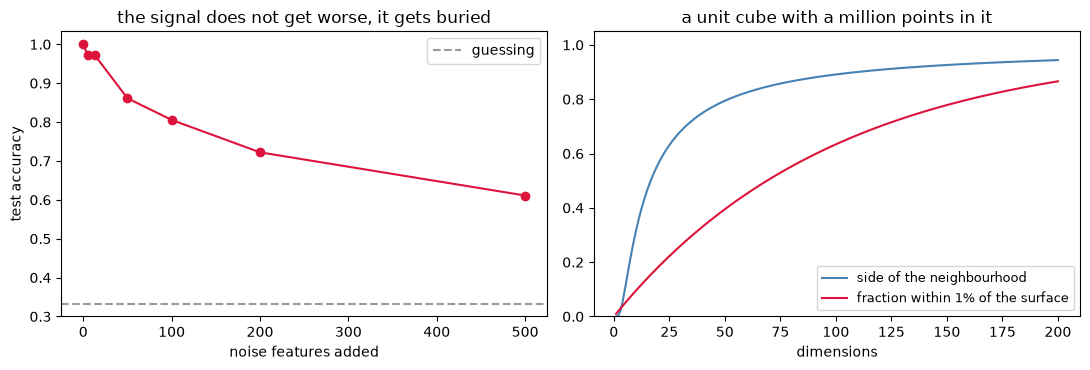


  dimensions   neighbourhood side   within 1% of surface
           2                0.003                  0.020
           3                0.022                  0.030
          10                0.316                  0.096
         100                0.891                  0.634
         200                0.944                  0.866


In [16]:
counts = [0, 5, 13, 50, 100, 200, 500]
accuracies = []
curse_rng = random.Random(0)

for extra in counts:
    data = [row + [curse_rng.gauss(0.0, 1.0) for _ in range(extra)] for row in X]
    curse_scaler = Standardiser.fit(take(data, train))
    model = KNearestNeighbours(5).fit(curse_scaler.transform(take(data, train)), y_train)
    score = accuracy(y_test, model.predict(curse_scaler.transform(take(data, test))))
    accuracies.append(score)
    print(f"13 real + {extra:>3} noise features: test accuracy {score:.3f}")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.8))
ax1.plot(counts, accuracies, marker="o", color="crimson")
ax1.axhline(1 / 3, color="0.6", ls="--", label="guessing")
ax1.set_xlabel("noise features added"), ax1.set_ylabel("test accuracy")
ax1.set_title("the signal does not get worse, it gets buried"), ax1.legend()

dimensions = list(range(1, 201))
ax2.plot(dimensions, [(10 / 1e6) ** (1 / d) for d in dimensions],
         color="steelblue", label="side of the neighbourhood")
ax2.plot(dimensions, [1 - 0.99 ** d for d in dimensions],
         color="crimson", label="fraction within 1% of the surface")
ax2.set_xlabel("dimensions"), ax2.set_ylim(0, 1.05), ax2.legend(fontsize=9)
ax2.set_title("a unit cube with a million points in it")
fig.tight_layout()
plt.show()

print(f"\n{'dimensions':>12}{'neighbourhood side':>21}{'within 1% of surface':>23}")
for d in (2, 3, 10, 100, 200):
    print(f"{d:>12}{(10 / 1e6) ** (1 / d):>21.3f}{1 - 0.99 ** d:>23.3f}")

The blue curve is the side length of the smallest cube holding the 10 nearest of a million points.
In a hundred dimensions it spans **89%** of the range of every feature — those points are not
"near" by any reading of the word, and the label kNN copies from them is close to arbitrary.

The red curve says almost every point is within 1% of the boundary, so nearly everything is an edge
case with no neighbours on one side.

This is also why kd-trees stop helping. Their whole advantage is discarding a subtree because the
splitting plane is farther away than the current best neighbour — and once the nearest neighbour is
89% of the way across the cube, no plane is ever far enough, so nothing gets pruned. The kd-tree
section measured it: from twelve features on, the tree looked at nearly every point anyway.

## Where this leaves us

- **kNN has no training phase and no assumptions**, and on well-scaled wine data it classifies the
  test set perfectly. Use it as the baseline before anything more elaborate.
- **Preprocessing outweighed the algorithm.** Scaling moved accuracy 0.722 to 1.000; no value of
  `k` mattered nearly as much.
- **`k = 1` scores 1.000 on its own training set**, which is what a perfect training score is
  usually worth.
- **One measurement is not a measurement.** A single cross-validation run could not rank `k` at all;
  twenty runs made the curve obvious. Report a mean and a spread.
- **A kd-tree is a tool for few dimensions.** It found the nearest of 100,000 points after 53
  distances in two dimensions, and measured 96% of the wine data in thirteen.
- **Accuracy hides the interesting part**, and on imbalanced data it actively misleads. The
  confusion matrix costs one line and says what actually happened.